Training Done
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3)]


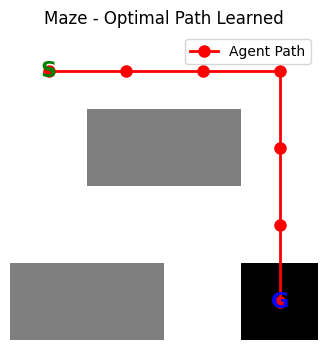

In [49]:
# EASIEST MAZE + PLOT - 1 Cell
import numpy as np
import matplotlib.pyplot as plt
import random

# 1. Maze: 0=free, 1=wall, 2=goal
maze = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0],
    [1, 1, 0, 2]
])

# 2. Q-Table + Moves
q_table = np.zeros((4, 4, 4))
moves = [(-1,0), (1,0), (0,-1), (0,1)] # Up, Down, Left, Right

# 3. Training - 300 episodes
for _ in range(300):
    r, c = 0, 0
    while True:
        a = random.randint(0,3) if random.random() < 0.3 else np.argmax(q_table[r,c])
        nr, nc = r + moves[a][0], c + moves[a][1]

        if nr<0 or nr>=4 or nc<0 or nc>=4 or maze[nr,nc]==1:
            reward, nr, nc = -10, r, c
        elif maze[nr,nc]==2:
            reward = 100
            q_table[r,c,a] += 0.1 * (reward - q_table[r,c,a])
            break
        else:
            reward = -1

        q_table[r,c,a] += 0.1 * (reward + 0.9*np.max(q_table[nr,nc]) - q_table[r,c,a])
        r, c = nr, nc

print("Training Done")

# 4. Find Best Path
r, c = 0, 0
path_r, path_c = [0], [0]
for _ in range(10):
    if maze[r,c]==2: break
    a = np.argmax(q_table[r,c])
    r, c = r + moves[a][0], c + moves[a][1]
    path_r.append(r)
    path_c.append(c)

print("Path:", list(zip(path_r, path_c)))

# 5. PLOT - Simple Maze + Path
plt.figure(figsize=(4,4))
plt.imshow(maze, cmap='gray_r') # Show maze
plt.plot(path_c, path_r, 'ro-', linewidth=2, markersize=8, label='Agent Path') # Red path
plt.text(0, 0, 'S', color='green', fontsize=16, ha='center', va='center', fontweight='bold')
plt.text(3, 3, 'G', color='blue', fontsize=16, ha='center', va='center', fontweight='bold')
plt.title('Maze - Optimal Path Learned')
plt.legend()
plt.axis('off')
plt.show()